# COMP8410 Advanced Topic in Artificial Intelligence

# Notebook 4 - Comment Moderation (Which comments should be removed on launch day?)

### Introduction

This notebook will use as an AI model can remove harrasment of the artisys without hiding real customer complaints in three language such as Korean, Thai, and English, especially on products launchday. Due to there are many people come to comments on social media platforms of artists company which can be different three way such as admire, complaints, or negative feedbacks.

In summary of comment type, 

| Comment type | Example | Correct action |
|---|---|---|
| **Praise** | "The hoodie is so pretty!" | keep |
| **Complaint** | "My keyring arrived broken, I want a refund" | **keep**: angry, but it is real customer feedback |
| **Attack** | "She is useless, leave the group" | remove |



There are mainly purpose to do such as:
* Protect Artist - there are so many news about K-pop industry that most of artist have mental illness till commit to suicide linked with all negative commenrs attack, referring from information since 2020 - 2026.
* Protect the interesting rate of products - people can be interest on product which will rely or depend on social media feedbacks as well. 



This notebook compares two open **guard LLMs** (language models trained to judge whether text is harmful):

| | System A - Standard System Overview | System B - Global System Overview | Baseline |
|---|---|---|---|
| Model | **Granite Guardian 3.1 2B** (IBM) | **Qwen3Guard-Gen 4B** (Alibaba Qwen) | **Keyword filter** |
| How it decides | answers **Yes / No** to "is this harmful?" | answers **Safe / Controversial / Unsafe** with a category | removes a comment if it contains a listed word |
| Languages (model card) | **English only** (trained and tested on English) | **119 languages and dialects**, including Korean and Thai | only the words in the list |



### Linked with COMP8410 Knowledge
* **Assignment brief Section 2.1:** NLP and LLM techniques; AI governance, safety, privacy and ethics.
* **Transformers / LLMs:** both guards are decoder LLMs; the decision is read from the probability of the first answer token.
* **Governance:** I measure fairness across languages and how often legitimate complaints are wrongly removed.

### Datasets (all public, no token)

1. **BEEP!** (Moon et al., 2020) -> Korean Language which show about comments on Korean entertainment news, labelled by humans
2. **KOLD** (Jeong et al., 2022) -> Korean which show about Korean online comments (news, YouTube) labelled for offensiveness 


**References**
- Jeong, Y., Oh, J., Lee, J., Ahn, J., Moon, J., Park, S., & Oh, A. (2022). KOLD: Korean Offensive Language Dataset. *Proceedings of EMNLP 2022*, 10818–10833. https://aclanthology.org/2022.emnlp-main.744
- Moon, J., Cho, W. I., & Lee, J. (2020). BEEP! Korean corpus of online news comments for toxic speech detection. *Proceedings of the Eighth International Workshop on Natural Language Processing for Social Media*, 25–31. https://aclanthology.org/2020.socialnlp-1.4
- Padhi, I., et al. (2024). Granite Guardian. *arXiv:2412.07724*. Model card: https://huggingface.co/ibm-granite/granite-guardian-3.1-2b
- Qwen Team (2025). Qwen3Guard technical report. Model card: https://huggingface.co/Qwen/Qwen3Guard-Gen-4B\
- J K. (2020, July 7). *Insiders question the effectiveness of disabling comments on entertainment news; "Sulli Act" reportedly no longer in talks*. Soompi. https://www.soompi.com/article/1411495wpp/insiders-question-the-effectiveness-of-disabling-comments-on-entertainment-news-sulli-act-reportedly-no-longer-in-talks
- Lee, J.-G. (2020, July 7). *Nate entertainment news comments end... Entertainment comments disappear from the three major portals*. Asia Economy. https://www.asiae.co.kr/en/article/2020070708070421262
- sl278838. (2020, February 19). *Naver to discontinue comments on entertainment articles and related keyword searches*. allkpop. https://www.allkpop.com/article/2020/02/naver-to-discontinue-comments-on-entertainment-articles-and-related-keyword-searches
- AKP Staff. (2025, November 6). K-pop ‘Idol Union’ set to launch this year, aiming to protect artists’ labor rights and mental health. allkpop. https://www.allkpop.com/article/2025/11/k-pop-idol-union-set-to-launch-this-year-aiming-to-protect-artists-labor-rights-and-mental-health
- Asia Economy. (2025, December 30). K-pop agencies take firm action against malicious commenters and stalkers targeting artists. https://www.asiae.co.kr/en/article/2025123016135779398
- Kim, J.-H. (2025, March 12). Academics call for societal shift in attitudes toward K-pop singers’ mental health. The Korea Herald. https://www.koreaherald.com/article/10440102
- Lee, J.-J. (2026, January 22). K-pop agencies fight malicious comments — why it’s not enough. The Korea Herald. https://www.koreaherald.com/article/10661023
- De La Cruz, B. (2023, December 6). Toxic beauty standards of Korean idols. Medium. https://medium.com/@bdelacruz1_2747/toxic-beauty-standards-of-korean-idols-5bdcf5e4ab83
- Sasaeng fan. (n.d.). In Wikipedia. Retrieved November 5, 2026, from https://en.wikipedia.org/wiki/Sasaeng_fan
- Vo, P. (2022, October 14). Young Kpop idols under extreme amounts of stress. The Nexus. https://wvnexus.org/opinions/young-kpop-idols-under-extreme-amounts-of-stress/

# 1. Import Libraries and Set-up

In [1]:
# Shared settings: identical in every notebook (if you change one, change all) 
from pathlib import Path
import os, sys, json, time, random, platform, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# Experiment Settings for seed
SEED = 42


SYSTEMS = {"A": "Standard System Overview", "B": "Global System Overview"}

**GPU Checking**
* Cost estimation for computing unit and GPU type
* All of the price references and Google Colab Information in **ENV_SETUP.ipynb**

In [2]:
COLAB_PRICE_PER_UNIT_USD = 9.99 / 100

COLAB_UNITS_PER_HOUR_BY_GPU = {"T4": 1.19, "L4": 1.71, "A100": 5.40}


# GPU Detection
try:

    import torch

    _gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

except ImportError:

    _gpu = "CPU"


# Compute the approximate GPU cost per hour in USD
GPU_HOURLY_USD = next(
    (u for k, u in COLAB_UNITS_PER_HOUR_BY_GPU.items() if k in _gpu), 0.0 ) * COLAB_PRICE_PER_UNIT_USD

In [3]:
#  Random Seed Function 
def set_seed(seed: int = SEED) -> None:

    
    random.seed(seed)

    np.random.seed(seed)

    try:
        import torch

        torch.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)

    except ImportError:
        
        pass

In [4]:
#  Device Detection Function 


def get_device() -> str:

    try:
        import torch

        if torch.cuda.is_available():

            return "cuda"

    except ImportError:
        pass

    return "cpu"



set_seed()


print(
    f"device: {get_device()} | "
    f"GPU: {_gpu} ≈ US${GPU_HOURLY_USD:.3f}/hour"
)

device: cuda | GPU: NVIDIA L4 ≈ US$0.171/hour


**Helper Function**

This will help me to check about run metadata (Dataset), timing, outcomes, which will use in all pairs model

So there is mainly feature:
* Check GPU 
* Model management
* Saved program environment
* GPU memory setuo
* Timimg measure
* Save final experiment result

In [5]:
# GPU Type and Capability
def gpu_dtype():

    import torch

    if torch.cuda.is_available():

        if torch.cuda.get_device_capability()[0] >= 8:
            return torch.bfloat16
        else:
            return torch.float16

    return torch.float32

In [6]:
# Transformers Output from AI model to Tensor Function - Model Management
def as_tensor(out):

    """get_*_features returns a tensor in transformers 4.x; newer versions may wrap it in an output object."""

    if hasattr(out, "pooler_output") and out.pooler_output is not None:

        return out.pooler_output

    if hasattr(out, "image_embeds"):
        
        return out.image_embeds

    if hasattr(out, "text_embeds"):

        return out.text_embeds

    return out if hasattr(out, "shape") else out[0]

In [7]:
# Store Environment Information Function 

def env_info():

    """Saved inside every result file as evidence of when and where it was produced."""


    info = {

        "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),

        "python": platform.python_version(),

        "os": platform.platform()

    }

    for pkg in ("torch", "transformers", "diffusers", "torch_geometric"):

        try:

            info[pkg] = __import__(pkg).__version__

        except Exception:

            info[pkg] = None

    try:

        import torch

        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None


    except Exception:

        info["gpu"] = None

    return info

In [8]:
# Logging Function for GPU Synchronization for Accurate Timing and Checking GPU working

def sync_gpu():

    try:

        import torch

        if torch.cuda.is_available():

            torch.cuda.synchronize()

    except ImportError:

        pass

In [9]:
# Free GPU Memory Function to Avoid Out of Memory Errors

def free_gpu():

    import gc

    gc.collect()

    try:

        import torch

        torch.cuda.empty_cache()

    except ImportError:

        pass

In [10]:

# Timer -> for measuring latency and peak GPU memory usage, leading to performance evaluation and cost analysis of AI models

class Timer:
    #  check model performance from Latency and Peak VRAM


    def __init__(self):
        # Constructor will initialize the Timer object and set default values for latencies and peak VRAM usage.

        self.latencies, self.peak_vram_gb = [], None

        try:
           # start checking GPU
            import torch

            if torch.cuda.is_available():
    
                torch.cuda.reset_peak_memory_stats()

        except ImportError:

            pass




    def add(self, seconds, n_items=1):
        # this will calculate the average time per item and store it in the latencies list for further analysis.

        self.latencies.extend([seconds / n_items] * n_items)


    def finish(self):
        # this function is called after all processing is done to finalize the timing and memory usage data.
        try:

         # check GPU again
            import torch

            if torch.cuda.is_available():

                torch.cuda.synchronize()


                self.peak_vram_gb = torch.cuda.max_memory_allocated() / 1024**3
               # check GPU Memory usage and convert to GB

        except ImportError:

            pass

        return self



    def business(self):

        # this function summarizes the business performance metrics of the AI model to provide insights for business decision-making and cost analysis.

        mean = float(np.mean(self.latencies)) if self.latencies else float("nan")
        # Compute the average latency in seconds for processing each item, and handle cases where there are no latencies recorded by returning NaN.

        return {

            "mean_latency_s": round(mean, 4),


            "p95_latency_s": round(float(np.percentile(self.latencies, 95)), 4) if self.latencies else None,
             # 95th percentile latency, indicating that 95% of the items were processed in this time or less. If there are no latencies recorded, it returns None.

            "gpu_hourly_usd": round(GPU_HOURLY_USD, 4),

            "cost_per_1000_usd": round(mean * 1000 / 3600 * GPU_HOURLY_USD, 4),

            "peak_vram_gb": None if self.peak_vram_gb is None else round(self.peak_vram_gb, 2),
          
        }

In [11]:
# JSON file handling function to manage data that cannot be directly converted to JSON, such as NumPy Scalars or special object types.
def _json_default(o):
    

    return o.item() if hasattr(o, "item") else str(o)

In [12]:
# Save Result Function

# Project folders: relative paths work on both Colab and Windows
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW = ROOT / "Datasets"
PROCESSED = RAW / "processed"
AMAZON_DIR = RAW / "Amazon2023_Merchandise_Data"
RESULTS = ROOT / "Results"
FIGURES, TABLES, METRICS = RESULTS / "figures", RESULTS / "tables", RESULTS / "metrics"
for _d in (PROCESSED, AMAZON_DIR, FIGURES, TABLES, METRICS):
    _d.mkdir(parents=True, exist_ok=True)


def save_result(task, system, model_id, technical, business,
                governance, notes="", items=None, extra=None):

    records = {

        "task": task,

        "system": system,

        "model_id": model_id,

        "technical": technical,

        "business": business,

        "governance": governance,

        "notes": notes,

        "env": env_info(),

        "extra": extra or {}

    }

    path = METRICS / f"{task}__{system}.json"

    path.write_text(
        json.dumps(
            records,
            indent=2,
            ensure_ascii=False,
            default=_json_default
        ),
        encoding="utf-8"
    )

    if items is not None:

        items.to_csv(
            TABLES / f"{task}__{system}_items.csv",
            index=False
        )

    print("saved", path)

    return records

# 2. Task Settings

All three systems read the same comments and give each one a **harm score between 0 and 1**.
Furthermore, A comment with a score of **0.5 or more is removed**. 

> For KOLD dataset, I will do upload it to Google Colab content as well due to I use both of Google environment such as Colab and Drive to work, because laptop limitation computer unit and memory unit. While BEEP! downloads automatically from GitHub.

In [14]:
TASK = "4_Comment_Moderation"

QUICK = True                          

MODELS = {
    "baseline_keyword": {"kind": "keyword", "id": "keyword-filter"},
    "A": {"kind": "granite", "id": "ibm-granite/granite-guardian-3.1-2b", "risk": "harm"},
    "B": {"kind": "qwen3guard", "id": "Qwen/Qwen3Guard-Gen-4B"},
}

RUN_SYSTEMS = ["baseline_keyword", "A", "B"]

BEEP_URL = "https://raw.githubusercontent.com/kocohub/korean-hate-speech/master/labeled/dev.tsv"
KOLD_PATH = RAW / "KOLD_Korean Offensive Language Dataset" / "kold_data.json" 

N_KOREAN = 120 if QUICK else 300                # comments taken of each dataset
N_SYNTHETIC_PER_LANG = 30 if QUICK else 90      # synthetic comments per language (three type of its)
THRESHOLD = 0.5                                 
BENIGN_FPR_MAX = 0.05                           # Rules remove at most 5 % of benign comments

# 3. Load Data and Create Evaluation Set

Labels: `1` = harmful (remove), `0` = benign (keep).

> KOLD will manual upload from drive and upload to colab same as Notebook 3 concepts dataset too

In [17]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
KOLD_PATH.parent.mkdir(parents=True, exist_ok=True)

if not KOLD_PATH.exists():
    uploaded = Path("/content/kold_data.json")

    if not uploaded.exists():
        files.upload()                                   # choose kold_data.json from my laptop

    if not uploaded.exists():
        raise FileNotFoundError("Please upload kold_data.json")

    shutil.copy2(uploaded, KOLD_PATH)

print("KOLD found:", KOLD_PATH.exists())
print("Dataset path:", KOLD_PATH)

KOLD found: True
Dataset path: /content/Datasets/KOLD_Korean Offensive Language Dataset/kold_data.json


**Synthetic comments & Clean Comments**

In this section, I will customize prompt comment in different language too which KOLD and BEEP mainly have Korean. So I will customize English and Thai into it.

> FYI, the reason that I use three languages due to I am unable to understand these three languages
> - Thai is my mother language, English is my second language, and Korean is my third language


In [25]:
# comments refer to member roles, so the test is about the business case, not one artist 
MEMBERS = {"english": ["the leader", "the main vocal", "the maknae", "the rapper", "the visual"],
           "thai": ["ลีดเดอร์", "เมนโวคอล", "มักเน่", "แร็ปเปอร์", "วิชวล"],
           "korean": ["리더", "메인보컬", "막내", "래퍼", "비주얼"]}
PRODUCTS = {"english": ["tote bag", "hoodie", "keyring", "photocard", "lightstick"],
            "thai": ["กระเป๋าผ้า", "ฮู้ด", "พวงกุญแจ", "โฟโต้การ์ด", "แท่งไฟ"],
            "korean": ["에코백", "후드티", "키링", "포토카드", "응원봉"]}

TEMPLATES = {
    "praise": {
        "english": ["The {p} is so pretty, {m} looks amazing in the photos!",
                    "Love the new {p}, best merch so far",
                    "Just got my {p}, the quality is really good"],
        "thai": ["{p}สวยมาก ชอบลายนี้ที่สุด เริสอะ {m}น่ารักมาก",
                 "ซื้อ{p}แล้ว คุณภาพดีมาก คุ้มค่า :)",
                 "{p}รอบนี้ดีที่สุดเลย!!"],
        "korean": ["{p} 너무 예뻐요 {m} 최고!",
               "이번 {p} 퀄리티 진짜 좋아요",
               "{p} 드디어 받았어요 너무 행복해요"]},
    "complaint": {
        "english": ["My {p} arrived broken, this is terrible service, I want a refund now",
                    "Worst packaging ever, the {p} was crushed. Fix your shipping!",
                    "Three weeks and my {p} still has not arrived, this store is a joke"],
        "thai": ["{p}มาถึงพัง แย่มาก ขอคืนเงินด่วน",
                  "ส่งช้ามาก {p}ยับหมด ผิดหวังกับร้านนี้สุดๆ T_T",
                  "สั่ง{p}มาสามอาทิตย์แล้วยังไม่ได้ของ บริการแย่มาก :(  "],
        "korean": ["{p}가 부서져서 왔어요 환불해 주세요",
               "배송 최악이에요 {p} 다 구겨졌어요 진짜 실망",
               "{p} 주문한 지 3주인데 아직도 안 왔어요 너무하네요"]},
    "attack": {
        "english": ["{m} is talentless, quit the group already, nobody wants you",
               "{m} should just disappear, so ugly and useless",
               "Nobody wants {m} here, the group is better without her"],
        "thai": ["{m}ไม่มีความสามารถ ออกจากวงไปเลย ไม่มีใครอยากเห็นหน้า ออกไปซะ!!",
               "{m}น่ารังเกียจ หายไปซะ ไม่ควรอยู่ในวงการ หน้าไม่อาย",
               "ไม่มีใครต้องการ{m}ในวงนี้หรอก ออกไปเหอะ เสียเวลาดู"],
        "korean": ["{m} 재능도 없으면서 그룹에서 나가라 아무도 너 안 좋아해",
               "{m} 진짜 꼴보기 싫다 사라져라",
               "{m} 없는 게 그룹한테 더 나아"]},
}


# synthetic comments (
def synthetic_comments(n_per_lang=N_SYNTHETIC_PER_LANG, seed=SEED):
    rng, rows = random.Random(seed), []
    for language in ("english", "korean", "thai"):
        for i in range(n_per_lang):
            cat = ("praise", "complaint", "attack")[i % 3]
            text = rng.choice(TEMPLATES[cat][language]).format(p=rng.choice(PRODUCTS[language]), m=rng.choice(MEMBERS[language]))
            text = text[0].upper() + text[1:]                
            if language == "korean" and rng.random() < 0.3:         # common in K-pop fandom
                text += " lol"
            rows.append({"text": text, "label": int(cat == "attack"), "language": language, "category": cat, "source": "synthetic"})
    return pd.DataFrame(rows)


# BEEP!: Korean entertainment-news comments 
def load_beep(n=N_KOREAN):
    cache = RAW / "BEEP" / "beep_dev.tsv"
    if not cache.exists():
        import requests
        cache.parent.mkdir(parents=True, exist_ok=True)
        cache.write_bytes(requests.get(BEEP_URL, timeout=60).content)
    d = pd.read_csv(cache, sep="\t").sample(frac=1, random_state=SEED).head(n)
    return pd.DataFrame({"text": d["comments"], "label": d["hate"].isin(["hate", "offensive"]).astype(int),
                         "language": "korean", "category": "beep_" + d["hate"], "source": "BEEP!"})


# KOLD: Korean offensive comments 
def load_kold(n=N_KOREAN):
    if not KOLD_PATH.exists():
        print("KOLD not found (optional):", KOLD_PATH)
        return None
    d = pd.DataFrame(json.loads(KOLD_PATH.read_text(encoding="utf-8")))
    d = d.sample(min(n, len(d)), random_state=SEED)
    return pd.DataFrame({"text": d["comment"], "label": d["OFF"].astype(bool).astype(int),
                         "language": "korean", "category": np.where(d["OFF"], "kold_offensive", "kold_none"), "source": "KOLD"})


parts = [load_beep(), load_kold(), synthetic_comments()]
data = pd.concat([p for p in parts if p is not None], ignore_index=True)
data["text"] = data["text"].astype(str).str.strip() # Clean Data Section
data.to_csv(PROCESSED / f"{TASK}__eval_set.csv", index=False)

print(f"{len(data)} comments")
display(pd.crosstab([data["source"], data["language"]], data["label"].map({0: "safe", 1: "harmful"}), margins=True))

330 comments


label               harmful  safe  All
source    language                    
BEEP!     korean         81    39  120
KOLD      korean         57    63  120
synthetic english        10    20   30
          korean         10    20   30
          thai           10    20   30
All                     168   162  330

**UNIT CHECKING**

Check of Evaluation Dataset Validity and Class Balance which these criteria rougly
-  every comment must contain text and a binary label (0 = benign, 1 = harmful). 
-  Each language must contain both classes so that per-language F1 can be evaluated.

PASS: 330 comments | share harmful by language: {'english': 0.33, 'korean': 0.55, 'thai': 0.33}

EVALUATION DATASET SUMMARY


,Safe,Harmful,Total,Harmful Rate (%)
language,,,,
english,20,10,30,33.33
korean,122,148,270,54.81
thai,20,10,30,33.33


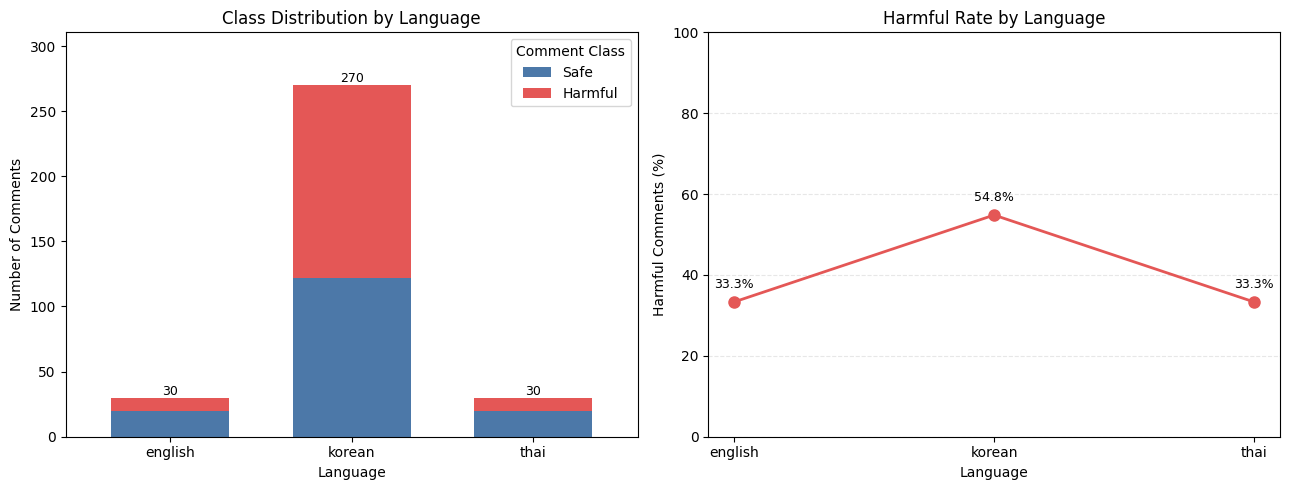

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

assert data["text"].str.len().gt(0).all(), "empty comments"
assert set(data["label"].unique()) <= {0, 1}, "labels must be 0/1"
per_language = data.groupby("language")["label"].agg(["min", "max"])
assert (per_language["min"] == 0).all() and (per_language["max"] == 1).all(), f"A language lacks one class:\n{per_language}"
pd.testing.assert_frame_equal(synthetic_comments(), synthetic_comments())          # same output every run
assert (data.query("category == 'complaint'")["label"] == 0).all(), "complaints must be safe"
print("PASS:", len(data), "comments | share harmful by language:", data.groupby("language")["label"].mean().round(2).to_dict())

# Prepare class distribution by language
class_counts = ( data.groupby(["language", "label"]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0).sort_index())

class_counts.columns = ["Safe", "Harmful"]
# Calculate harmful rate each language
harmful_rate = (data.groupby("language")["label"].mean().mul(100).sort_index())

# Display evaluation dataset statistics
dataset_summary = class_counts.copy()
dataset_summary["Total"] = dataset_summary.sum(axis=1)
dataset_summary["Harmful Rate (%)"] = harmful_rate.round(2)

print("\nEVALUATION DATASET SUMMARY")
display(dataset_summary)

# Visualize class distribution and harmful rate
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_counts.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=["#4c78a8", "#e45756"],
    width=0.65
)

axes[0].set_title("Class Distribution by Language")
axes[0].set_xlabel("Language")
axes[0].set_ylabel("Number of Comments")
axes[0].legend(title="Comment Class")
axes[0].tick_params(axis="x", rotation=0)

for i, total in enumerate(class_counts.sum(axis=1)):
    axes[0].text(
        i,
        total,
        f"{total:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

axes[0].set_ylim(
    0,
    max(class_counts.sum(axis=1).max() * 1.15, 1)
)

# Plot harmful rate across languages
x = np.arange(len(harmful_rate))

axes[1].plot(x,harmful_rate.values, marker="o", linewidth=2, markersize=8, color="#e45756")

axes[1].set_xticks(x, harmful_rate.index)
axes[1].set_title("Harmful Rate by Language")
axes[1].set_xlabel("Language")
axes[1].set_ylabel("Harmful Comments (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

for i, rate in enumerate(harmful_rate.values): axes[1].annotate(f"{rate:.1f}%", (i, rate), xytext=(0, 10), textcoords="offset points", ha="center",fontsize=9)

plt.tight_layout()
plt.show()

# 4. Models Performance

Each system returns a **harm score from 0 to 1**:

| System | Score | Reading Concept |
|---|---|---|
| Baseline | 1 if a listed word appears, else 0 | simple string search |
| A - Granite Guardian | "Yes" | the model is asked whether the comment is harmful (risk = **harm**) -> we read the probability of its first answer token, **Yes** vs **No** (method from the model card) |
| B - Qwen3Guard | 1 − "Safe" | the model writes **Safety: Safe / Controversial / Unsafe** -> we read the probability of the label token. **Controversial** counts as harmful (the model card's strict mode) |

In [28]:
import re

KEYWORDS = [
    # English
    "trash", "useless", "talentless", "ugly", "stupid", "disgusting", "hate you", "kill yourself", "die",
    # Thai
    "ไม่มีความสามารถ", "น่ารังเกียจ", "หายไป", "โง่", "ขยะ", "ไปตาย",
    # Korean
    "쓰레기", "꺼져", "사라져", "병신", "죽어", "못생", "꼴보기 싫", "재능도 없",
]


class Keyword_Filter:
    def score(self, text):
        t = str(text).lower()
        return float(any(k in t for k in KEYWORDS))


class Granite_Guardian:
    #System A: P('Yes' = harmful) from the first answer token.

    def __init__(self, model_id, risk="harm"):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch, self.risk = torch, risk
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=gpu_dtype()).to(get_device()).eval()
        # all vocabulary tokens that read as "yes" or "no" (e.g. "Yes", " yes")
        vocab = self.tok.get_vocab()
        self.yes_ids = [i for t, i in vocab.items() if self.tok.convert_tokens_to_string([t]).strip().lower() == "yes"]
        self.no_ids = [i for t, i in vocab.items() if self.tok.convert_tokens_to_string([t]).strip().lower() == "no"]

    def score(self, text):
        messages = [{"role": "user", "content": str(text)}]
        prompt = self.tok.apply_chat_template(messages, guardian_config={"risk_name": self.risk},
                                              add_generation_prompt=True, tokenize=False)
        ids = self.tok(prompt, return_tensors="pt").to(self.model.device)
        with self.torch.no_grad():
            logits = self.model(**ids).logits[0, -1].float()
        pair = self.torch.stack([self.torch.logsumexp(logits[self.no_ids], 0),
                                 self.torch.logsumexp(logits[self.yes_ids], 0)])
        return float(self.torch.softmax(pair, 0)[1])


class Qwen3_Guard:
    # System B: 1 - P('Safe') at the label token of 'Safety: <label>'."""

    LABELS = ("Safe", "Controversial", "Unsafe")

    def __init__(self, model_id):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch = torch
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=gpu_dtype()).to(get_device()).eval()
        # first token of each label, with and without a leading space
        self.label_ids = {lab: sorted({self.tok.encode(v, add_special_tokens=False)[0] for v in (lab, " " + lab)})
                          for lab in self.LABELS}
        self.all_ids = {i for ids in self.label_ids.values() for i in ids}

    def generate(self, text, max_new_tokens=8):
        messages = [{"role": "user", "content": str(text)}]
        prompt = self.tok.apply_chat_template(messages, tokenize=False)
        ids = self.tok([prompt], return_tensors="pt").to(self.model.device)
        with self.torch.no_grad():
            out = self.model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                                      output_scores=True, return_dict_in_generate=True)
        return out, ids["input_ids"].shape[1]

    def score(self, text):
        out, n_in = self.generate(text)
        for step, logits in enumerate(out.scores):                       # find the step that writes the label
            if out.sequences[0, n_in + step].item() in self.all_ids:
                l = logits[0].float()
                per_label = self.torch.stack([self.torch.logsumexp(l[self.label_ids[lab]], 0) for lab in self.LABELS])
                return float(1 - self.torch.softmax(per_label, 0)[0])    # 1 - P(Safe)
        answer = self.tok.decode(out.sequences[0, n_in:], skip_special_tokens=True)
        return 0.0 if re.search(r"Safety:\s*Safe", answer) else 1.0     # fallback

    def explain(self, text):
        # Full answer with the harm category, used in the live demo.
        out, n_in = self.generate(text, max_new_tokens=32)
        return self.tok.decode(out.sequences[0, n_in:], skip_special_tokens=True).strip()


def load_guard(spec):
    if spec["kind"] == "keyword":
        return Keyword_Filter()
    if spec["kind"] == "granite":
        return Granite_Guardian(spec["id"], spec.get("risk", "harm"))
    return Qwen3_Guard(spec["id"])


# remove emails, URLs and @handles before any comment is shown or saved (privacy)
def strip_pii(text):
    text = re.sub(r"\S+@\S+", "[email]", str(text))
    text = re.sub(r"https?://\S+", "[url]", text)
    return re.sub(r"@\w+", "@[user]", text)

# 5. Metrics

| Dimension | Metric |
|---|---|
| Technical | **F1**, precision, recall -> check how good model can find harmful comments (harmful = positive class) |
| Technical | **AUPRC** -> check how good the model score is, without using 0.5 threshold |
| Governance | **safe_fpr** -> how many safe comments got removed by mistake (**target ≤ 5%**) |
| Governance | **complaint_fpr** -> how many normal complaints got removed by mistake |
| Governance | **language_f1_gap** -> difference between highest and lowest macro-F1 from Korean, Thai and English |


In [32]:
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score


def false_positive_rate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    neg = y_true == 0
    return float(y_pred[neg].mean()) if neg.any() else float("nan")


def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


def evaluate(scores, frame, threshold=THRESHOLD):
    items = frame.assign(score=np.asarray(scores, dtype=float), y_true=frame["label"].to_numpy())
    items["y_pred"] = (items["score"] >= threshold).astype(int)
    yt, yp = items["y_true"], items["y_pred"]
    technical = {"f1": float(f1_score(yt, yp, zero_division=0)),
                 "precision": float(precision_score(yt, yp, zero_division=0)),
                 "recall": float(recall_score(yt, yp, zero_division=0)),
                 "accuracy": float((yt == yp).mean()),
                 "auprc": float(average_precision_score(yt, items["score"])) if yt.nunique() == 2 else float("nan")}
    by_lang = {l: macro_f1(g["y_true"], g["y_pred"]) for l, g in items.groupby("language")}
    by_source = {s: macro_f1(g["y_true"], g["y_pred"]) for s, g in items.groupby("source")}
    complaints = items[items["category"] == "complaint"]
    governance = {"safe_fpr": false_positive_rate(yt, yp),
                  "complaint_fpr": float(complaints["y_pred"].mean()) if len(complaints) else float("nan"),
                  "language_f1_gap": max(by_lang.values()) - min(by_lang.values()),
                  "f1_by_language": by_lang, "f1_by_source": by_source}
    return technical, governance, items

**UNIT CHECKIN**

To ensure metric work correclty

PASS: metrics and privacy filter behave as expected


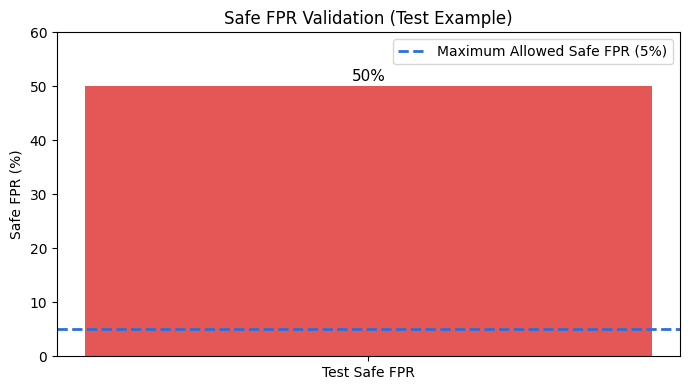

In [33]:
import matplotlib.pyplot as plt

# Check -> Safe FPR calculation is correct
assert false_positive_rate([0, 0, 1, 1], [1, 0, 1, 0]) == 0.5

# small data for testing
test_fromdatasample = pd.DataFrame({"text": list("abcd"), "label": [0, 0, 1, 1], "language": ["english", "english", "thai", "thai"],
                    "category": ["praise", "complaint", "attack", "attack"], "source": "toy"})

# Test the metrics using example scores
t, g, _ = evaluate([0.9, 0.1, 0.8, 0.7], test_fromdatasample)
assert t["recall"] == 1.0 and g["safe_fpr"] == 0.5 and g["complaint_fpr"] == 0.0

# Check if emails/ usernames/ URLs are removed
assert strip_pii("mail a@b.com @fan1 https://x.y") == "mail [email] @[user] [url]"

# Check if Keyword Filter only returns 0 or 1
assert set(Keyword_Filter().score(x) for x in data["text"]) <= {0.0, 1.0}

print("PASS: metrics and privacy filter behave as expected")

# Get Safe FPR and maximum allowed rate
test_safe_fpr = g["safe_fpr"] * 100
business_limit = BENIGN_FPR_MAX * 100

# Create a bar chart for the  example
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Test Safe FPR"],
    [test_safe_fpr],
    color="#e45756",
    width=0.45
)

# Show the maximum allowed Safe FPR
ax.axhline(
    business_limit,
    color="#2a6fdb",
    linestyle="--",
    linewidth=2,
    label=f"Maximum Allowed Safe FPR ({business_limit:.0f}%)"
)

# Show the percentage above the bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{test_safe_fpr:.0f}%",
        ha="center",
        fontsize=11
    )

# Add chart title and labels
ax.set_title("Safe FPR Validation (Test Example)")
ax.set_ylabel("Safe FPR (%)")
ax.set_ylim(0, max(test_safe_fpr * 1.2, 10))
ax.legend()

plt.tight_layout()
plt.show()

**Safe FPR Test Explanation**

Graph uses a small test dataset to check the Safe FPR calculation. 

- Then The result is 50% because one of two safe comments was removed by mistake. The 5% line is the business limit.

> FYI, This is only a test example, not the real performance of System A or System B.

# 6. Execute the three systems

In [34]:
conclusion = {}

for system in RUN_SYSTEMS:
    spec = MODELS[system]
    guard = load_guard(spec)
    guard.score(data["text"].iloc[0])                       

    # Measure model performance and time
    timer, scores = Timer(), []
    for text in data["text"]:
        t0 = time.perf_counter()
        scores.append(guard.score(text))
        sync_gpu()
        timer.add(time.perf_counter() - t0)

    # Evaluate and remove personal information
    technical, governance, items = evaluate(scores, data)
    items["text"] = items["text"].map(strip_pii)

    # Save results each systems
    save_result(TASK, system, spec["id"], technical, timer.finish().business(), governance, items=items,
                notes=f"threshold={THRESHOLD}; n={len(data)}; sources={data['source'].value_counts().to_dict()}")

    # Collect metrics for comparison
    conclusion[system] = {**technical, **timer.business(),
                       **{k: v for k, v in governance.items() if not k.startswith("f1_by")},
                       "f1_by_language": governance["f1_by_language"], "f1_by_source": governance["f1_by_source"]}
    print(f"done: {system:17s} F1 = {technical['f1']:.3f} | safe_fpr = {governance['safe_fpr']:.3f}")
    del guard; free_gpu()

# Create and save the summary table
results = pd.DataFrame(conclusion).T
columns = ["f1", "precision", "recall", "auprc", "safe_fpr", "complaint_fpr", "language_f1_gap",
        "mean_latency_s", "cost_per_1000_usd", "peak_vram_gb"]
results[columns] = results[columns].astype(float)
results[columns].to_csv(TABLES / f"{TASK}__summary.csv")
display(results[columns].round(3))

saved /content/Results/metrics/4_Comment_Moderation__baseline_keyword.json
done: baseline_keyword  F1 = 0.226 | safe_fpr = 0.031


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/87.0 [00:00<?, ?B/s]

... (20 outputs left out)

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/161 [00:00<?, ?B/s]

saved /content/Results/metrics/4_Comment_Moderation__B.json
done: B                 F1 = 0.739 | safe_fpr = 0.142


,f1,precision,recall,auprc,safe_fpr,complaint_fpr,language_f1_gap,mean_latency_s,cost_per_1000_usd,peak_vram_gb
baseline_keyword,0.226,0.815,0.131,0.549,0.031,0.067,0.552,0.000,0.000,0.00
A,0.576,0.757,0.464,0.762,0.154,0.300,0.258,0.050,0.002,4.79
B,0.739,0.830,0.667,0.836,0.142,0.000,0.293,0.459,0.022,7.64


**UNIT_TEST** 

To check if all comments have valid score 

PASS which all have complete, valid scores for ['baseline_keyword', 'A', 'B']


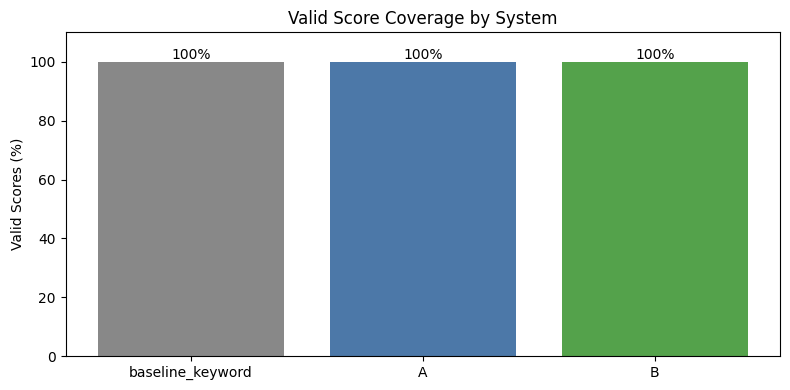

In [35]:
import matplotlib.pyplot as plt

valid_counts_scores = {}

for system in RUN_SYSTEMS:
    items = pd.read_csv(TABLES / f"{TASK}__{system}_items.csv")
    assert len(items) == len(data), f"{system}: {len(items)} scores for {len(data)} comments"
    assert items["score"].between(0, 1).all(), f"{system}: scores outside [0, 1]"
    valid_counts_scores[system] = items["score"].between(0, 1).sum()

print("PASS which all have complete, valid scores for", RUN_SYSTEMS)

# Calculate valid score percentage
coverage = {system: count / len(data) * 100 for system, count in valid_counts_scores.items()}

# Plot score coverage for each system
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(coverage.keys(), coverage.values(), color=["#888888", "#4c78a8", "#54a24b"])

# Show percentage on each bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.0f}%",
        ha="center"
    )

ax.set_title("Valid Score Coverage by System")
ax.set_ylabel("Valid Scores (%)")
ax.set_ylim(0, 110)

plt.tight_layout()
plt.show()

# 7. Overalls outcome 

* **By language:** Compare how each system perform on Korean, Thai and English, helping to  check the fairness across languages.
* **By source:** Compare the results from synthetic comments, BEEP! and KOLD , ensuing Real comments may be harder because they have slang and more complex language.
* **Over-moderation:** Check how many Safe comments and normal complaints got removed by mistake -> Safe FPR should not be higher than 5%.

,Baseline (Foundation),System A (Granite Guardian),System B (Qwen3Guard)
english,0.670,0.861,1.000
korean,0.369,0.603,0.707
thai,0.921,0.753,1.000


,Baseline (Foundation),System A (Granite Guardian),System B (Qwen3Guard)
BEEP!,0.273,0.575,0.680
KOLD,0.363,0.591,0.700
synthetic,0.788,0.775,0.935


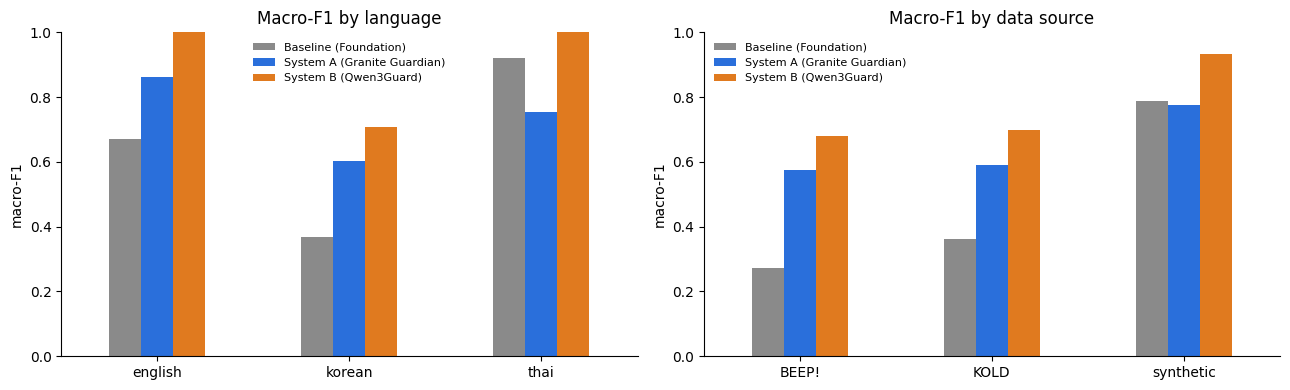

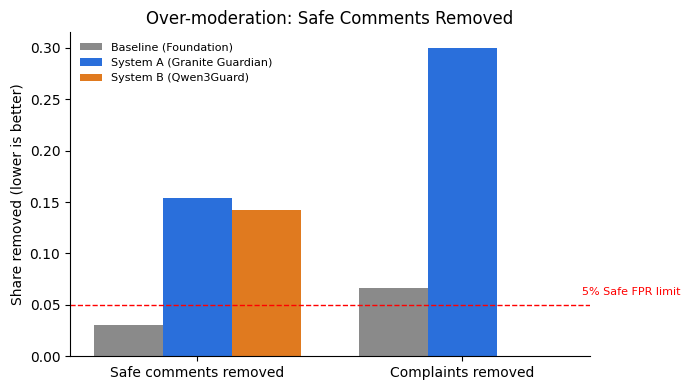

In [36]:
import matplotlib.pyplot as plt

COLORS = {"baseline_keyword": "#8a8a8a", "A": "#2a6fdb", "B": "#e07a1f"}
LABELS = {"baseline_keyword": "Baseline (Foundation)", "A": "System A (Granite Guardian)", "B": "System B (Qwen3Guard)"}

# f1
by_lang = pd.DataFrame({LABELS[s]: conclusion[s]["f1_by_language"] for s in RUN_SYSTEMS})
by_source = pd.DataFrame({LABELS[s]: conclusion[s]["f1_by_source"] for s in RUN_SYSTEMS})
display(by_lang.round(3)); display(by_source.round(3))

# Macro f1 compaing
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, table, title in [(axes[0], by_lang, "Macro-F1 by language"), (axes[1], by_source, "Macro-F1 by data source")]:
    table.plot.bar(ax=ax, rot=0, color=[COLORS[s] for s in RUN_SYSTEMS])
    ax.set_ylim(0, 1); ax.set_ylabel("macro-F1"); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / f"{TASK}__f1_by_language_and_source.png", dpi=200, bbox_inches="tight")
plt.show()

# remove rates
fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(2)
for i, s in enumerate(RUN_SYSTEMS):
    vals = [conclusion[s]["safe_fpr"], conclusion[s]["complaint_fpr"]]
    ax.bar(x_pos + (i - 1) * 0.26, vals, 0.26, color=COLORS[s], label=LABELS[s])

# Show the maximum allowed Safe FPR
ax.axhline(BENIGN_FPR_MAX, ls="--", c="red", lw=1)
ax.text(1.45, BENIGN_FPR_MAX + 0.01, "5% Safe FPR limit", color="red", fontsize=8)

ax.set_xticks(x_pos, ["Safe comments removed", "Complaints removed"])
ax.set_ylabel("Share removed (lower is better)")
ax.set_title("Over-moderation: Safe Comments Removed")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURES / f"{TASK}__over_moderation.png", dpi=200, bbox_inches="tight")
plt.show()

# 8. Error Analysis

Check wrong predictions from System A and System B. 

To look at errors like harmful comments not detected, Safe comments removed by mistake, and possible problems with Korean, Thai, or English slang 

In [37]:
# Check wrong predictions from System A and B
for system in ["A", "B"]:
    items = pd.read_csv(TABLES / f"{TASK}__{system}_items.csv")

    # Find comments wrong predictions
    wrong = items[items["y_true"] != items["y_pred"]].copy()
    wrong["error"] = np.where(wrong["y_true"] == 1, "missed harmful", "removed safe")

    # Show error counts 
    print(f"\n{LABELS[system]}: {len(wrong)} errors of {len(items)}")
    display(wrong.groupby(["language", "source", "error"]).size().rename("count").to_frame())

    # Show examples 
    display(wrong[["language", "source", "category", "score", "error", "text"]].sort_values("score").head(8))


System A (Granite Guardian): 115 errors of 330


count
language source    error                
english  synthetic removed safe        4
korean   BEEP!     missed harmful     46
                   removed safe        5
         KOLD      missed harmful     35
                   removed safe       11
         synthetic missed harmful      7
thai     synthetic missed harmful      2
                   removed safe        5

,language,source,category,score,error,text
31,korean,BEEP!,beep_offensive,0.075872,missed harmful,솔직히 너무 이뻐졌는데...
73,korean,BEEP!,beep_offensive,0.106696,missed harmful,캐릭터는 좋은데 연기가 좀 아쉽던데.
115,korean,BEEP!,beep_offensive,0.106704,missed harmful,그래도 더 빼야죠....
290,korean,synthetic,attack,0.119217,missed harmful,리더 없는 게 그룹한테 더 나아
281,korean,synthetic,attack,0.119217,missed harmful,리더 없는 게 그룹한테 더 나아
236,korean,KOLD,kold_offensive,0.132970,missed harmful,설미 이 밥팅아 옛날에는 남북이 똑같았어
293,korean,synthetic,attack,0.132974,missed harmful,메인보컬 없는 게 그룹한테 더 나아
11,korean,BEEP!,beep_offensive,0.148056,missed harmful,본인의 선택아닌가...왜 눈물짜냐..



System B (Qwen3Guard): 79 errors of 330


count
language source    error                
korean   BEEP!     missed harmful     34
                   removed safe        4
         KOLD      missed harmful     17
                   removed safe       19
         synthetic missed harmful      5

,language,source,category,score,error,text
73,korean,BEEP!,beep_offensive,0.001089,missed harmful,캐릭터는 좋은데 연기가 좀 아쉽던데.
11,korean,BEEP!,beep_offensive,0.002356,missed harmful,본인의 선택아닌가...왜 눈물짜냐..
74,korean,BEEP!,beep_offensive,0.002409,missed harmful,이거 아직도 하?
16,korean,BEEP!,beep_offensive,0.003090,missed harmful,울것두 많다??
31,korean,BEEP!,beep_offensive,0.005230,missed harmful,솔직히 너무 이뻐졌는데...
207,korean,KOLD,kold_offensive,0.018020,missed harmful,폐미는 이기적논리 오지고
58,korean,BEEP!,beep_offensive,0.021207,missed harmful,현지 반응 별로던데 노래도 이상하고 춤도 난해하다고.. 국내에서도 지코한테 1위 다...
284,korean,synthetic,attack,0.021965,missed harmful,비주얼 없는 게 그룹한테 더 나아


# 9. Conclusion

In [39]:
print("." * 55)
print("FINAL COMMENT MODERATION OVERALL RESULTS")
print("." * 55)

# dataset information
print(f"\n1. DATA: {len(data)} comments |", data["source"].value_counts().to_dict(),
      "| languages:", data["language"].value_counts().to_dict())

# overall model results
print("\n2. OVERALL RESULTS")
display(results[columns].round(3))

# Check the 5% Safe FPR limit
print("\n3. GO / NO-GO RULE (Safe comments removed ≤ 5 %)")
for s in RUN_SYSTEMS:
    fpr = conclusion[s]["safe_fpr"]
    print(f"  {LABELS[s]:30s} safe_fpr = {fpr:6.1%} -> {'PASS' if fpr <= BENIGN_FPR_MAX else 'FAIL'}")

# Compare System A and B
print("\n4.System A vs System B")
a, b = conclusion["A"], conclusion["B"]
print(f"  F1: A {a['f1']:.3f} vs B {b['f1']:.3f} | language gap: A {a['language_f1_gap']:.3f} vs B {b['language_f1_gap']:.3f}")
print(f"  Cost per 1,000 comments: A US${a['cost_per_1000_usd']:.4f} vs B US${b['cost_per_1000_usd']:.4f}")

# Save
final = results[columns].round(4)
final.to_csv(TABLES / f"{TASK}__final_summary.csv")
print("\nFinal summary saved:", TABLES / f"{TASK}__final_summary.csv")

.......................................................
FINAL COMMENT MODERATION OVERALL RESULTS
.......................................................

1. DATA: 330 comments | {'BEEP!': 120, 'KOLD': 120, 'synthetic': 90} | languages: {'korean': 270, 'english': 30, 'thai': 30}

2. OVERALL RESULTS


,f1,precision,recall,auprc,safe_fpr,complaint_fpr,language_f1_gap,mean_latency_s,cost_per_1000_usd,peak_vram_gb
baseline_keyword,0.226,0.815,0.131,0.549,0.031,0.067,0.552,0.000,0.000,0.00
A,0.576,0.757,0.464,0.762,0.154,0.300,0.258,0.050,0.002,4.79
B,0.739,0.830,0.667,0.836,0.142,0.000,0.293,0.459,0.022,7.64



3. GO / NO-GO RULE (Safe comments removed ≤ 5 %)
  Baseline (Foundation)          safe_fpr =   3.1% -> PASS
  System A (Granite Guardian)    safe_fpr =  15.4% -> FAIL
  System B (Qwen3Guard)          safe_fpr =  14.2% -> FAIL

4.System A vs System B
  F1: A 0.576 vs B 0.739 | language gap: A 0.258 vs B 0.293
  Cost per 1,000 comments: A US$0.0024 vs B US$0.0218

Final summary saved: /content/Results/tables/4_Comment_Moderation__final_summary.csv


In [ ]:
rows = []
for system in ["A", "B"]:
    items = pd.read_csv(TABLES / f"{TASK}__{system}_items.csv")
    safe = items["y_true"] == 0
    for th in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
        pred = (items["score"] >= th).astype(int)
        rows.append({"system": system, "threshold": th,
                     "f1": f1_score(items["y_true"], pred, zero_division=0),
                     "recall": recall_score(items["y_true"], pred, zero_division=0),
                     "safe_fpr": pred[safe].mean(),
                     "complaint_fpr": pred[items["category"] == "complaint"].mean()})

sweep = pd.DataFrame(rows)
sweep["passes_5pct"] = sweep["safe_fpr"] <= BENIGN_FPR_MAX
sweep.to_csv(TABLES / f"{TASK}__threshold_sweep.csv", index=False)
display(sweep.round(3))

,system,threshold,f1,recall,safe_fpr,complaint_fpr,passes_5pct
0,A,0.50,0.576,0.464,0.154,0.3,False
1,A,0.60,0.445,0.304,0.062,0.1,False
2,A,0.70,0.290,0.173,0.019,0.0,True
3,A,0.80,0.122,0.065,0.006,0.0,True
4,A,0.90,0.047,0.024,0.000,0.0,True
5,A,0.95,0.035,0.018,0.000,0.0,True
6,B,0.50,0.739,0.667,0.142,0.0,False
7,B,0.60,0.676,0.571,0.123,0.0,False
8,B,0.70,0.640,0.524,0.117,0.0,False
9,B,0.80,0.585,0.452,0.099,0.0,False


# 10. Save Google Drive and Load into Zip

In [41]:
from google.colab import drive
import zipfile

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
DRIVE_OUTPUT = Path("/content/drive/MyDrive/Kpop_MerchAI/Comment_Moderation")
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)


ZIP_PATH = DRIVE_OUTPUT / "4_Comment_Moderation_Results.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
  
    for file in TABLES.glob(f"{TASK}*.csv"):
        zipf.write(file, arcname=f"tables/{file.name}")
  
    for file in FIGURES.glob(f"{TASK}*.png"):
        zipf.write(file, arcname=f"figures/{file.name}")

    for file in METRICS.glob(f"{TASK}*.json"):
        zipf.write(file, arcname=f"metrics/{file.name}")

print("ZIP saved successfully!")
print("Location:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

ZIP saved successfully!
Location: /content/drive/MyDrive/Kpop_MerchAI/Comment_Moderation/4_Comment_Moderation_Results.zip
Size: 0.16 MB


# 11. Live Demo

In [46]:
# Example of Comments
EX_COMMENTS = [
    ("en", "keep",   "The new ECLYRA hoodie is so soft, Lumi looks amazing in the photos!"),
    ("en", "keep",   "My tote bag arrived ripped and nobody answers my emails. Refund me now!"),
    ("en", "remove", "Nobody wants Cyra here, the group is better without her"),
    ("th", "keep",   "พวงกุญแจมาถึงหักเลย แย่มาก ขอเงินคืนด่วน"),
    ("th", "remove", "พวกแก ไม่มีความสามารถ ออกจากวงไปเลย"),
    ("ko", "keep",   "키링 너무 귀여워요 Sela 최고 lol"),
    ("ko", "remove", "Even 진짜 꼴보기 싫다 사라져라"),
]

# Create demo table
EX_table = pd.DataFrame(EX_COMMENTS, columns=["language", "expected", "comment"])
qwen_answer = None

# Test all systems on demo comments
for system in RUN_SYSTEMS:
    guard = load_guard(MODELS[system])
    t0 = time.perf_counter()
    scores = [guard.score(c) for c in EX_table["comment"]]
    secs = (time.perf_counter() - t0) / len(EX_table)

    # Show KEEP or REMOVE with scores
    EX_table[system] = [f"{'REMOVE' if s >= THRESHOLD else 'KEEP'} ({s:.2f})" for s in scores]
    EX_table[system + "_ok"] = [("REMOVE" if s >= THRESHOLD else "KEEP").lower() == e for s, e in zip(scores, EX_table["expected"])]

    # Get Qwen3Guard explanation
    if system == "B":
        qwen_answer = [guard.explain(c).replace("\n", " | ") for c in EX_table["comment"]]

    print(f"{LABELS[system]:30s} {secs:.3f} s per comment")
    del guard; free_gpu()

# Add Qwen3Guard answers
EX_table["Qwen3Guard says"] = qwen_answer

# Mark correct and wrong predictions
for s in RUN_SYSTEMS:
    EX_table[s] = [f"{v} {'correct' if ok else 'mistake'}" for v, ok in zip(EX_table[s], EX_table.pop(s + "_ok"))]

# Remove personal information before display
EX_table["comment"] = EX_table["comment"].map(strip_pii)
EX_table["Qwen3Guard says"] = EX_table["Qwen3Guard says"].map(strip_pii)

display(EX_table.rename(columns=LABELS))

Baseline (Foundation)          0.000 s per comment


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

System A (Granite Guardian)    0.053 s per comment


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

System B (Qwen3Guard)          0.459 s per comment


,language,expected,comment,Baseline (Foundation),System A (Granite Guardian),System B (Qwen3Guard),Qwen3Guard says
0,en,keep,"The new ECLYRA hoodie is so soft, Lumi looks a...",REMOVE (1.00) mistake,KEEP (0.01) correct,KEEP (0.00) correct,Safety: Safe | Categories: None
1,en,keep,My tote bag arrived ripped and nobody answers ...,KEEP (0.00) correct,REMOVE (0.56) mistake,KEEP (0.00) correct,Safety: Safe | Categories: None
2,en,remove,"Nobody wants Cyra here, the group is better wi...",KEEP (0.00) mistake,REMOVE (0.73) correct,KEEP (0.38) mistake,Safety: Safe | Categories: None
3,th,keep,พวงกุญแจมาถึงหักเลย แย่มาก ขอเงินคืนด่วน,KEEP (0.00) correct,REMOVE (0.71) mistake,KEEP (0.02) correct,Safety: Safe | Categories: None
4,th,remove,พวกแก ไม่มีความสามารถ ออกจากวงไปเลย,REMOVE (1.00) correct,KEEP (0.32) mistake,REMOVE (0.53) correct,Safety: Controversial | Categories: Unethical ...
5,ko,keep,키링 너무 귀여워요 Sela 최고 lol,KEEP (0.00) correct,KEEP (0.11) correct,KEEP (0.04) correct,Safety: Safe | Categories: None
6,ko,remove,Even 진짜 꼴보기 싫다 사라져라,REMOVE (1.00) correct,KEEP (0.41) mistake,REMOVE (0.53) correct,Safety: Controversial | Categories: Suicide & ...
